Author:  
Manuel Eugenio Morocho Cayamcela, PhD

# **Unsupervised Learning**
## Mall Customer Clustering with KMeans

### **Introduction**

This activity introduces clustering using the `mall_customers.csv` dataset, which contains information about shopping mall customers, including a variable that represents their spending behavior.

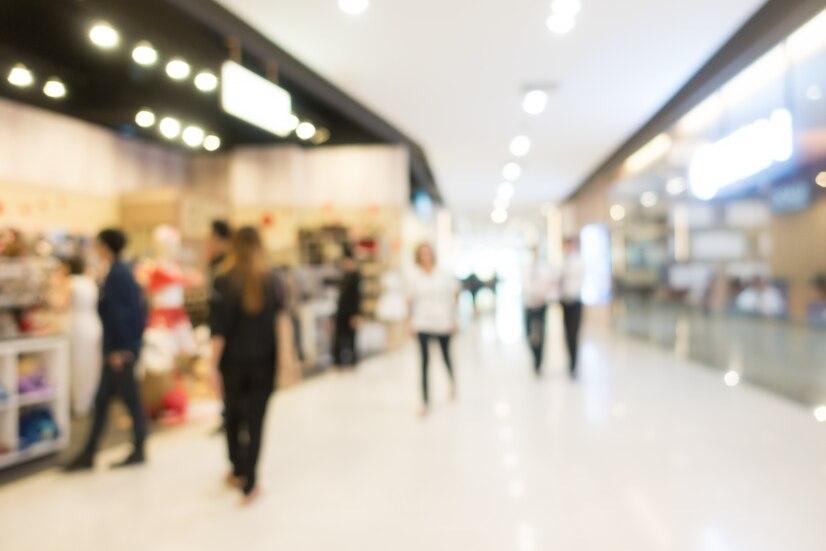

The `mall_customers.csv` dataset contains the following variables:

1. `CustomerID`: A unique identifier for each customer. It is an integer that increases by 1 for each customer.

2. `Gender`: The customer's gender. This is a categorical variable with two possible values: 'Male' and 'Female'.

3. `Age`: The customer's age. This is a numerical variable.

4. `Annual Income (k$)`: The customer's annual income in thousands of dollars. This is a numerical variable.

5. `Spending Score (1-100)`: The customer's spending score on a scale from 1 to 100. This is a numerical variable that indicates how much the customer spends or reflects their purchasing behavior.

The spending score measures how much a customer spends at a particular business over a given period. This metric is essential for understanding customer purchasing behavior and segmenting customers into groups with similar characteristics. But how is this score calculated, and where does it come from in a real company?

The spending score is derived from a combination of factors, such as visit frequency, average purchase value, and total spending over a specific period. Businesses often use customer tracking systems, such as loyalty programs, loyalty cards, or point-of-sale (POS) systems, to collect purchase data. These systems record each customer transaction, including the amount spent, items purchased, and visit frequency.

Using this information, businesses can calculate the spending score in various ways, such as assigning points to each purchase based on its value or frequency, or using more complex algorithms that consider multiple variables. The goal is to create a metric that accurately and meaningfully reflects each customer's purchasing behavior.

In the real world, spending scores are used across many industries, including retail, restaurants, hotels, and financial services. Businesses use them to better understand customers, identify purchasing patterns, design targeted marketing strategies, and improve the customer experience.

### **Content**

#### Import the required packages

In [1]:
# Install the required packages
%pip install scikit-learn
%pip install "pandas<3"
%pip install matplotlib
%pip install seaborn
%pip install ipywidgets
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the required packages
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#### Load the dataset

In [3]:
# Load the 'mall_customers.csv' dataset
customers = pd.read_csv('datasets\mall_customers.csv')

#### Display the first 10 rows of the loaded dataset

In [4]:
# Display the first rows
customers.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [5]:
# Display information about the dataset
customers.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


array([[<Axes: title={'center': 'CustomerID'}>,
        <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Annual Income (k$)'}>,
        <Axes: title={'center': 'Spending Score (1-100)'}>]], dtype=object)

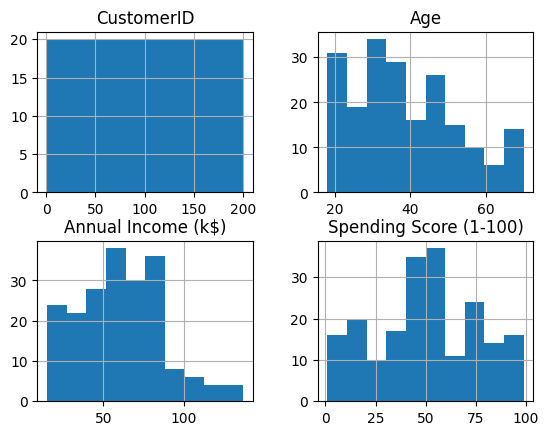

In [6]:
# Display histograms of the variables
customers.hist()

#### Remove columns that do not provide useful information for the analysis

The `CustomerID` column is a unique identifier for each customer. In most cases, identifiers like this do not provide useful information for data analysis or data mining models because they are not related to the other variables. Therefore, this column is commonly removed before analysis.

The pandas `drop` method removes the specified column (`'CustomerID'`) from the DataFrame. The `axis=1` argument indicates that we want to remove a column rather than a row. The resulting DataFrame is assigned back to the `customers` variable.

In [7]:
# Remove the 'CustomerID' column
customers = customers.drop('CustomerID', axis=1)
customers.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
5,Female,22,17,76
6,Female,35,18,6
7,Female,23,18,94
8,Male,64,19,3
9,Female,30,19,72


#### Encode the categorical 'Gender' column

We use the pandas `replace` method to replace values in the `Gender` column of the `customers` DataFrame.

- `customers['Gender']`: Selects the `Gender` column from the `customers` DataFrame.

- `replace({'Female': 0, 'Male': 1})`: Replaces values in the column according to the provided mapping. In this case, it replaces 'Female' with 0 and 'Male' with 1. This is called label encoding.

The purpose of this code is to convert the categorical `Gender` variable into a numerical variable, which is useful for calculating correlations between variables.

In [8]:
# Encode the 'Gender' variable
customers['Gender'] = customers['Gender'].replace({'Female': 0, 'Male': 1})
customers.head(10)

C:\Users\CheJ\AppData\Local\Temp\ipykernel_43056\3822190155.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  customers['Gender'] = customers['Gender'].replace({'Female': 0, 'Male': 1})


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40
5,0,22,17,76
6,0,35,18,6
7,0,23,18,94
8,1,64,19,3
9,0,30,19,72


#### Use `fg-data-profiling` to profile the data

The `fg-data-profiling` tool (formerly `ydata-profiling`, imported as `data_profiling`) is very useful for exploratory data analysis. This Python library generates detailed data profiles from a pandas DataFrame, providing a quick, comprehensive overview of the data structure, relationships, and distributions.

With `fg-data-profiling`, you can generate a comprehensive report from your dataset with just a few lines of code. The report includes descriptive statistics, variable distributions, correlations, missing values, and more. This can be extremely useful at the start of any data analysis or data mining project because it helps you understand your data before preprocessing or modeling.

Keep in mind that `fg-data-profiling` is a data analysis tool and does not replace careful analysis or a thorough understanding of your data. Always verify and understand the results it provides.

In [9]:
# Remove the deprecated ydata-profiling package: it ships a module with the same name as fg-data-profiling and both packages should not coexist in the same environment
%pip uninstall -y ydata-profiling

# Install the fg-data-profiling library (renamed successor of ydata-profiling)
%pip install fg-data-profiling

# Import ProfileReport from data_profiling (new import name; 'ydata_profiling' is deprecated)
from data_profiling import ProfileReport

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


- `customers`: The pandas DataFrame to profile.

- `title='Customer Data Profile Report'`: Sets the report title.

- `explorative=True`: Indicates that the report should be exploratory, including more information and analysis than a standard profiling report.

- `progress_bar=False`: Disables the progress bars shown while the report is generated (they are interactive widgets that some editors, such as VS Code, cannot display without downloading extra files).

The data profiling report provides a quick overview of your dataset, including data types, unique values, missing values, descriptive statistics, correlations, and variable distributions.

To display the report, call the `customer_profile` object in a Jupyter Notebook cell.

In [10]:
# Generate the data profiling report
# progress_bar=False disables the ipywidgets progress bars, which VS Code can only render
# after downloading the widget scripts from a third-party CDN.
customer_profile = ProfileReport(customers, title='Customer Data Profile Report', explorative=True, progress_bar=False)

In [11]:
# Display the data profiling report
customer_profile.to_notebook_iframe()

100%|██████████| 4/4 [00:00<00:00, 20.99it/s]


In [12]:
customer_profile.to_file('customer_profile_report.html')

#### Plot the distributions of the variables

The distribution of variables in a dataset can provide valuable information about its characteristics. Here are some things to examine:

**Central tendency**: The mean and median indicate where the data are centered.

**Dispersion**: The standard deviation and interquartile range indicate how spread out the data are around the mean.

**Skewness**: A left or right skew may indicate outliers or a non-uniform distribution.

**Outliers**: Values significantly distant from the rest of the data may indicate measurement errors or natural variation.

**Multimodal distribution**: More than one peak may indicate subgroups within the data.

The scatter plot of `Annual Income (k$)` and `Spending Score (1-100)` reveals visible data groupings, suggesting that there are groups of customers with similar spending behavior relative to their annual income.

We create a new DataFrame containing only these two variables to examine these groupings more closely and apply clustering techniques to identify and define the groups more formally.

This can provide valuable information for marketing strategy by allowing customers to be segmented according to their spending behavior and income. This, in turn, can inform decisions about targeted offers and promotions, personalized customer communications, and more.

In [13]:
# Create a DataFrame containing only the 'Annual Income (k$)' and 'Spending Score (1-100)' columns
income_spending = customers[['Annual Income (k$)', 'Spending Score (1-100)']]
income_spending.head(10)

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
5,17,76
6,18,6
7,18,94
8,19,3
9,19,72


#### Plot the distributions of 'Annual Income (k$)' and 'Spending Score (1-100)'

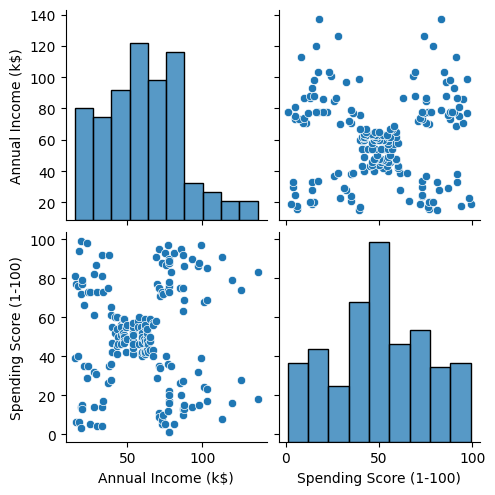

In [14]:
# Plot the distributions in income_spending
sns.pairplot(income_spending)

#### Cluster the 'income_spending' DataFrame using the KMeans algorithm

We use KMeans clustering on the `income_spending` DataFrame to find 2 clusters, then add the cluster labels to the data.

- `kmeans_model = KMeans(n_clusters=2)`: Creates a KMeans model with 2 clusters. The number of clusters is a parameter that must be specified.

- `kmeans_model.fit(income_spending)`: Fits the model to the `income_spending` data. KMeans attempts to find cluster centers that minimize the variance within each cluster.

- `income_spending['Cluster'] = kmeans_model.labels_`: After fitting the model, the `labels_` attribute provides the cluster label for each data point. This line adds the labels as a new column in the `income_spending` DataFrame.

- `income_spending.head(10)`: Displays the first 10 rows of the `income_spending` DataFrame, now including the `Cluster` column.

In [15]:
# Instantiate the KMeans model
kmeans_model = KMeans(n_clusters=2, random_state=75)

# Fit the model to the data
kmeans_model.fit(income_spending)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",75
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[

In [16]:
# Copy the 'income_spending' DataFrame to preserve the original and add the clusters
income_spending_cluster = income_spending.copy()

# Get the cluster labels assigned to each customer
income_spending_cluster['Cluster'] = kmeans_model.labels_

# Display the first rows of 'income_spending_cluster'
income_spending_cluster.head(10)

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,1
1,15,81,1
2,16,6,1
3,16,77,1
4,17,40,1
5,17,76,1
6,18,6,1
7,18,94,1
8,19,3,1
9,19,72,1


In [17]:
income_spending_cluster.tail(10)

,Annual Income (k$),Spending Score (1-100),Cluster
190,103,23,0
191,103,69,0
192,113,8,0
193,113,91,0
194,120,16,0
195,120,79,0
196,126,28,0
197,126,74,0
198,137,18,0
199,137,83,0


We create a pair plot of the `income_spending` variables and color the points according to the clusters identified by KMeans. This helps us visualize how the clusters are distributed in the variable space.

- `sns.pairplot(income_spending)`: Creates a pair plot of all variables in the DataFrame. A pair plot shows the relationship between each pair of variables in a dataset.

- `hue='Cluster'`: Specifies that points in the plot should be colored according to the `Cluster` column. This makes it possible to visualize the distribution of clusters for each pair of variables.

- `palette='viridis'`: Sets the color palette for the clusters. 'viridis' is a perceptually uniform palette that is easy to interpret.

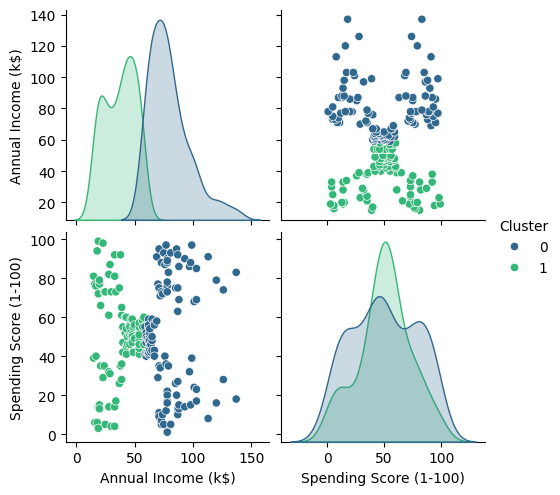

In [18]:
# Display the clusters generated by the KMeans model
sns.pairplot(income_spending_cluster, hue='Cluster', palette='viridis')

In [19]:
# Get the inertia of the KMeans model
inertia = kmeans_model.inertia_
inertia

181363.59595959593

Finally, we can use the previously fitted KMeans model to predict the cluster of a new customer based on their features.

- `new_customer = [ , ]`: Creates a list representing a new customer's data. The values correspond to the customer's annual income and spending score.

- `new_customer_cluster = kmeans_model.predict([new_customer])`: Uses the KMeans model's `predict` method to predict which cluster the new customer belongs to. The method takes a list of lists as input, where each inner list represents one customer's data. Here, the input contains only one customer: `[new_customer]`.

- `print('The new customer belongs to cluster:', new_customer_cluster)`: Prints the cluster assigned to the new customer. The `predict` method returns a list of cluster labels, one for each customer in the input. Here, the list contains a single label.

In [20]:
# New customer with Annual Income (k$) = 50 and Spending Score (1-100) = 50
new_customer_cluster = kmeans_model.predict([[50, 50]])
new_customer_cluster

c:\Users\CheJ\anaconda3\envs\mcd\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1], dtype=int32)

### **Group Assignment**

We can see that 2 may not be the optimal value of $k$. Let's try to find the best value of $k$ using the elbow method. This method involves running the KMeans clustering algorithm for a range of $k$ values and then plotting the number of clusters against the sum of squared distances within each cluster (inertia).

> Inertia is calculated by measuring the distance between a data point and its centroid, squaring the distance, and summing those squared distances for all data points in the cluster.

The 'elbow' in this plot—the inflection point where the rate of decrease becomes significantly smaller—may indicate a good value for $k$.

### **Code (4 points)**

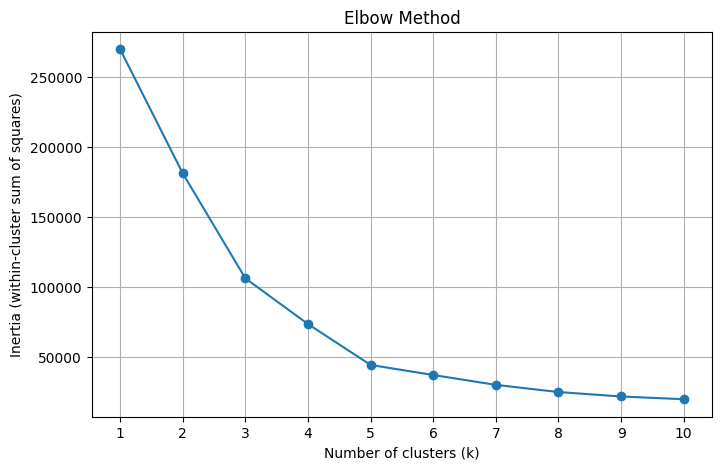

,k,Inertia,Decrease from previous k (%)
0,1,269981.280000,NaN
1,2,181363.595960,32.8
2,3,106348.373062,41.4
3,4,73679.789039,30.7
4,5,44448.455448,39.7
5,6,37265.865205,16.2
6,7,30227.606513,18.9
7,8,25095.703210,17.0
8,9,21913.929201,12.7
9,10,19968.359199,8.9


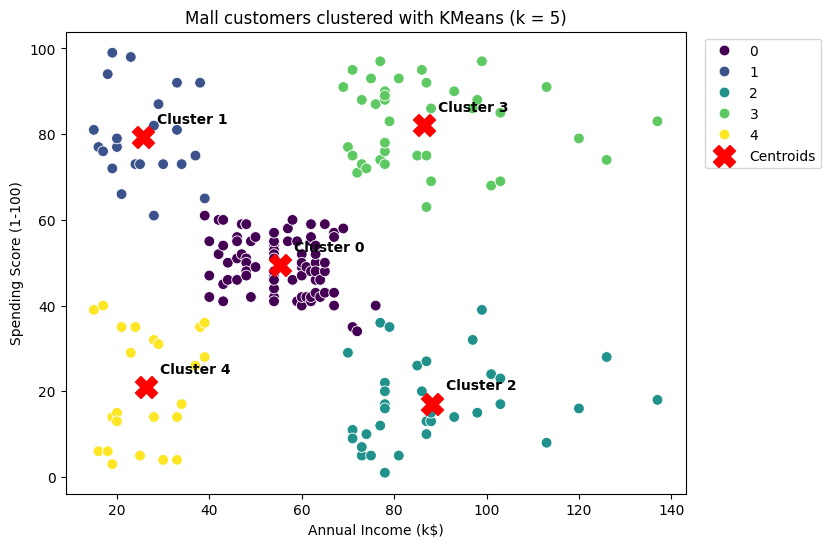

,Customers,Mean_Income_k,Mean_Spending_Score,Mean_Age,Male_Proportion
Cluster,,,,,
0,81,55.3,49.5,42.7,0.4
1,22,25.7,79.4,25.3,0.4
2,35,88.2,17.1,41.1,0.5
3,39,86.5,82.1,32.7,0.5
4,23,26.3,20.9,45.2,0.4


Inertia with k = 5 : 44448.5


In [ ]:
# Write your code here to find the optimal number of clusters using the elbow method.

# Step 1: Fit KMeans for a range of k values and store the inertia of each model n_init=10 runs KMeans 10 times with different initial centroids and keeps the best result, which makes the inertia values more stable.
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=75, n_init=10)
    model.fit(income_spending)
    inertias.append(model.inertia_)

# Step 2: Plot the elbow curve (number of clusters vs. inertia)
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Step 3: Table with the inertia and its percentage decrease for each k. The elbow is the k after which adding one more cluster reduces the inertia only slightly.
elbow_table = pd.DataFrame({'k': list(k_values), 'Inertia': inertias})
elbow_table['Decrease from previous k (%)'] = (-elbow_table['Inertia'].pct_change() * 100).round(1)
display(elbow_table)

# Step 4: Train the final KMeans model with the selected k From k=5 onwards the curve flattens: the inertia drops ~40% from k=4 to k=5, but only ~16% from k=5 to k=6. We select k=5.
optimal_k = 5
kmeans_model = KMeans(n_clusters=optimal_k, random_state=75, n_init=10)
kmeans_model.fit(income_spending)

# Step 5: Add the new cluster labels to the data
income_spending_cluster = income_spending.copy()
income_spending_cluster['Cluster'] = kmeans_model.labels_

# Step 6: Visualize the clusters and their centroids
centroids = kmeans_model.cluster_centers_

plt.figure(figsize=(8, 6))
sns.scatterplot(data=income_spending_cluster, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='viridis', s=60)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=250, label='Centroids')
for i, (x, y) in enumerate(centroids):
    plt.annotate(f'Cluster {i}', (x, y), textcoords='offset points', xytext=(10, 10),
                 fontweight='bold')
plt.title(f'Mall customers clustered with KMeans (k = {optimal_k})')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

# Step 7: Describe each cluster (average values and number of customers) 'customers' has the same index as 'income_spending', so we can also look at Age and Gender.
cluster_profile = customers.copy()
cluster_profile['Cluster'] = kmeans_model.labels_
cluster_summary = cluster_profile.groupby('Cluster').agg(
    Customers=('Age', 'size'),
    Mean_Income_k=('Annual Income (k$)', 'mean'),
    Mean_Spending_Score=('Spending Score (1-100)', 'mean'),
    Mean_Age=('Age', 'mean'),
    Male_Proportion=('Gender', 'mean'),
).round(1)
display(cluster_summary)

# Inertia of the final model
print('Inertia with k =', optimal_k, ':', round(kmeans_model.inertia_, 1))

Analysis Questions - New Dataset

Assessment Rubric (10 points)

Phase 1 - Dataset and Features (3 points)
1 point: The dataset is locally sourced, and its source is identified.
1 point: Every dataset variable is described.
1 point: The features selected for the model are justified.

Phase 2 - KMeans Modeling (4 points)
2 points: The elbow method is applied to a range of k values, and the plot and selected k are provided.
2 points: KMeans is fitted using the selected k, and the resulting clusters are visualized.

Phase 3 - Findings (3 points)
1 point each: Three findings are stated, and each is supported by the clustering results.

### **Analysis Questions - Mall Customers Dataset (6 points)**

***1. Which customer group would you focus on?***

**Answer:**

With $k = 5$, KMeans divides the customers into five groups according to their annual income and spending score (see the centroid table above):

| Group (described by its centroid) | Income | Spending | Customers | Mean age |
|---|---|---|---|---|
| Average income – average spending | ≈ 55 k\$ | ≈ 50 | 81 | ≈ 43 |
| High income – high spending | ≈ 87 k\$ | ≈ 82 | 39 | ≈ 33 |
| High income – low spending | ≈ 88 k\$ | ≈ 17 | 35 | ≈ 41 |
| Low income – low spending | ≈ 26 k\$ | ≈ 21 | 23 | ≈ 45 |
| Low income – high spending | ≈ 26 k\$ | ≈ 79 | 22 | ≈ 25 |

I would focus on the **high income – low spending** group. These customers have the purchasing power (≈ 88 k\$ per year, similar to the best customers of the mall), but their spending score is the lowest of all groups (≈ 17). In other words, it is the group with the largest gap between what they **could** spend and what they actually spend, so it has the highest growth potential. It is also a relatively large group (35 customers, 17.5 % of the sample).

At the same time, the **high income – high spending** group should not be ignored: it is currently the most valuable group, so the goal there is retention, keeping them loyal, rather than growth.

***2. What actionable strategies could we recommend to increase spending at the shopping mall?***

**Answer:**

The advantage of clustering is that each group can receive a different strategy instead of a single campaign for everyone:

1. **High income – low spending (main target):** first, find out why they spend little (short surveys, analysis of which stores they visit, etc). Then offer them what this profile values: premium or exclusive brands, personalized offers based on their purchase history, VIP services (preferential parking, private events). The objective is to convert part of this group into high spenders.

2. **High income – high spending:** retention. A loyalty program with exclusive benefits (early access to sales, special events, points with real value) helps keep these customers and their spending.

3. **Average income – average spending (largest group, 81 customers):** because of its size, small increases in spending have a large total impact. In this case we can apply bundle promotions ("buy 2, get a discount"), cross-selling between stores, and events that increase the frequency of visits.

4. **Low income – high spending (youngest group, ≈ 25 years):** they already spend a lot relative to their income, so the strategy should focus on loyalty through value, student or youth discounts, digital channels (app, social networks) and entertainment. It would not be wise to push them to spend more than they can afford, since we can provoque them to stop spending at all.

5. **Low income – low spending:** low-cost actions: discount days, offers on essential products and value-for-money promotions to keep them coming to the mall.

Finally, the results of each campaign should be measured (for example, comparing the spending score before and after) and the clustering repeated periodically, since customer behavior changes over time.

***3. Which group would a new customer with an annual income (k$) of 110 and a spending score of 21 belong to?***

In [22]:
# Create a record with the new customer's values and assign it to a cluster using the trained KMeans model.
new_customer = [110, 21]
# Use the KMeans model's predict method to predict the cluster of the new customer.
new_customer_cluster = kmeans_model.predict([new_customer])

print('The new customer belongs to cluster:', new_customer_cluster[0])
print('Centroid of that cluster (Income k$, Spending Score):', kmeans_model.cluster_centers_[new_customer_cluster[0]].round(1))

The new customer belongs to cluster: 2
Centroid of that cluster (Income k$, Spending Score): [88.2 17.1]


c:\Users\CheJ\anaconda3\envs\mcd\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


**Answer:**

The `k = 5` model assigns the new customer (annual income = 110 k\$, spending score = 21) to the cluster whose centroid is approximately **(88 k\$, 17)**, that is, the **high income – low spending** group.